# Path A, P17 — stop, resume and start rates (Oct 28, 2026)

**Spec (pre-registered; not changed after seeing results):**

Path A, Step 4, P17: estimate the stop / resume / start rates for the simulator.

Context: the Step 4 simulator (minimal model) has 4 player states:
- halted (including the initial halt at s = 0);
- moving (one step per interface tick);
- at the wall (|s| = 1);
- reversing (2 forced steps).

Moving <-> halted is driven by two constant rates, lam_stop and lam_resume.
The first move is the first resume. This task estimates the rates from the logs.
All definitions below are pre-registered: do not change them after seeing results.

Data: load_runs("behavior") = G-train only, bots and incomplete runs kept,
whole-second files dropped. Rows = human seats only; bot positions still count
as neighbors. Do not load G-val, Ring or CT.

1. src/slider/motion.py
   motion_spells(run, iface) -> per human seat:
   - Halt: a gap g between the seat's consecutive own steps, followed by
     k own steps (in the file's step units), holds a halt of g - k\*dt.
     Count it if > dt/2.
   - dt per interface:
     - lab v09: the round's tick (interface.py, per-round speed, file fallback);
     - old CL: 0.1 s, with 0.02 steps;
     - CC: raw rows, dt = 1 / file pace.
   - Moving (stop at-risk) time = own steps \* dt. Exclude:
     - time at the wall (|s| = 1);
     - mid-event spans: from a step against the direction until it resolves
       as a probe or a confirmed reversal (reuse detect_events / resolve_times, m = 2);
     - time before the first move.
   - Halted (resume at-risk) time = halt time mid-slider after the first move,
     excluding mid-event. Each halt's exit:
     - resume (next step in the same direction) = event;
     - reversal, probe or round end = censored.
   - Start: delay from round start to the first own step; first-move direction;
     the neighbors' majority side just before it = sign(sum of sign(s_j)) over
     neighbors with s_j != 0 (none moved, or a tie -> NaN).
2. rates_table(runs), per interface (lab_v09, old_cl, cc) and pooled ("shared"):
   - lam_stop = stops / moving seconds;
   - lam_resume = resumes / all halted seconds;
   - lam_start = first moves / pre-first-move seconds.

   95% CI: 1,000 resamples of groups, stratified by dataset (EL/CL/CC), seed 573.
3. notebooks/path1/p17_motion.ipynb
   - First cell: this spec, as markdown.
   - Save results/tables/p17_rates.csv.
   - Kaplan-Meier survival curves, log y-axis, per interface, for halt durations
     (non-resume exits censored) and for start delays
     -> results/figures/p17_survival.png. Report the mean and SD of each.
   - First-move statistic: among first moves with a defined neighbor majority,
     the share going toward it, with a group-bootstrap 95% CI.
   - Print the verdicts of the two locked rules:
     (a) Start rule: separate lam_start if its CI is disjoint from lam_resume's CI
         in >= 2 of the 3 interfaces; otherwise start = first resume.
     (b) Direction rule: CI lower bound > 0.5 -> "follow neighbors";
         otherwise "coin flip".
4. tests/test_motion.py, synthetic lab path with dt = 0.1:
   - a 0.5 s gap followed by 1 step -> one halt of 0.4 s;
   - a 0.2 s gap followed by 2 steps -> no halt;
   - moving time = steps \* 0.1.
5. Check, per interface: moving + halted + at wall + mid-event + pre-first-move
   = total human player time to round_end (fraught.round_end), within 1%.


## Choices the spec leaves open

Fixed in `motion.py` before any rate was computed.

- **Round start = t = 0** (the round clock). Lab files log a row only on a change, so the first row can come seconds later (one old-CL round's first row is at 67.44 s, and it still times out at 300 s). Each seat's path starts at (t = 0, s = 0); a seat already off 0 at the first logged row made its first move by then.
- **Start delay** = the gap from t = 0 to the first own step, minus k\*dt of that step (at least 0): the initial halt, measured like every other halt. A seat that never moves is censored at round_end.
- **Stop** = a halt in halted time that comes right after a step in moving time. A halt right after a mid-event step (e.g. the step that resolves a probe) is halted time but not a stop.
- **Exits:** the next own step opens no event -> resume; it opens a probe / reversal -> that exit; it opens an event the round end leaves unresolved -> `unresolved` (censored like probe and reversal); no next step -> `round_end`. In old CL (0.02 steps) a step back that does not change round(10 s) is not an event (`detect_events` works on round(10 s)), so the halt before it ends in a resume.
- **Order of the states** when two apply: pre-first-move, then mid-event, then at the wall. A step is `k*dt`; a step away from the wall opens an event, so it is mid-event.
- **Bootstrap:** per interface, its own groups (log files) are drawn within dataset; shared, all 39 groups within EL, CL, CC. Old CL has 2 groups, so its CIs are crude. The first-move CI uses the same draws (1,000, seed 573).
- **Mean and SD** of the survival panels: over the completed spells (resumed halts, observed first moves), next to 1 / lam.


## Correction (Oct 29, 2026): F1b

A bug against the locked spec ("Moving (stop at-risk) time ... Exclude: time at the wall"): `motion_spells` counted a step that lands on the wall (|s| = 1) as moving time, although a halt after it is at the wall and can never be a stop. Such a step is now wall time (`motion.py`, `tests/test_motion.py`). Found by the P23 parameter recovery. The notebook was rerun with the same spec, seed (573) and bootstrap (1,000 resamples). The old table is kept as `results/tables/p17_rates_v1.csv`; the old -> new comparison is at the end.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from slider import config, motion
from slider import slider_logs as sl
from slider.stats import kaplan_meier

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)

runs, table = sl.load_runs("behavior")                  # roles={"train"}: G-train only, no G-val, Ring or CT
assert set(table["role"]) == {"train"}
print(len(runs), "rounds,", table["file"].nunique(), "groups", table.groupby("dataset")["file"].nunique().to_dict(),
      "| bot rounds:", int(table["has_bot"].sum()), "| incomplete:", int((table["end"] == "incomplete").sum()))
seats, halts = motion.motion_table(runs)
print(len(seats), "human seats,", len(halts), "halts in halted time")
seats.groupby(["interface", "dt"]).size().rename("seats").to_frame().T

244 rounds, 39 groups {'CC': 17, 'CL': 11, 'EL': 11} | bot rounds: 42 | incomplete: 9


1662 human seats, 32263 halts in halted time


interface       cc                             lab_v09                     old_cl
dt        0.030030 0.030960 0.033003 0.034014 0.050000 0.100000 0.200000 0.100000
seats          113       54      696      106      112      476       21       84

## Check: time by state = human player time to round_end, per interface (within 1%)

In [2]:
check = motion.time_check(seats)
assert check["ok"].all()
check.round(4)

,interface,pre_s,moving_s,halted_s,wall_s,mid_s,total_s,residual_share,ok
0,lab_v09,1920.4700,3367.2500,6375.9000,26800.0700,2781.9200,41021.680,-0.0055,True
1,old_cl,1050.5400,1897.5000,1882.3300,4976.8700,613.2700,10357.270,-0.0061,True
2,cc,4564.6462,1325.6862,6009.5436,31223.1871,2151.0824,45228.462,-0.0010,True
3,shared,7535.6562,6590.4362,14267.7736,63000.1271,5546.2724,96607.412,-0.0034,True


## Rates (95% CI: 1,000 stratified group resamples, seed 573)

In [3]:
rates = motion.rates_table(runs)
rates.to_csv(config.P17_RATES, index=False)
print("halt exits:")
print(halts.groupby(["interface", "exit"]).size().unstack(fill_value=0).loc[motion.INTERFACES])
rates.round(4)

halt exits:
exit       probe  resume  reversal  round_end  unresolved
interface                                                
lab_v09      174   11273       985          2           0
old_cl        70    3267       235          2           1
cc           149   15319       781          5           0


,interface,rate,events,exposure_s,estimate,ci_low,ci_high,groups,seats
0,lab_v09,lam_stop,10974,3367.2500,3.2590,2.6811,3.7774,20,609
1,lab_v09,lam_resume,11273,6375.9000,1.7681,1.4773,2.0651,20,609
2,lab_v09,lam_start,609,1920.4700,0.3171,0.2675,0.3714,20,609
3,old_cl,lam_stop,3423,1897.5000,1.8040,1.7468,1.9188,2,84
4,old_cl,lam_resume,3267,1882.3300,1.7356,1.5600,2.1657,2,84
5,old_cl,lam_start,84,1050.5400,0.0800,0.0563,0.1378,2,84
6,cc,lam_stop,14717,1325.6862,11.1014,9.4200,12.9311,17,969
7,cc,lam_resume,15319,6009.5436,2.5491,2.1826,2.9911,17,969
8,cc,lam_start,930,4564.6462,0.2037,0.1834,0.2280,17,969
9,shared,lam_stop,29114,6590.4362,4.4176,3.4670,5.6503,39,1662


## Kaplan-Meier survival: halt durations and start delays

Dashed: exp(-lam t) at the interface's estimate (lam_resume, lam_start).

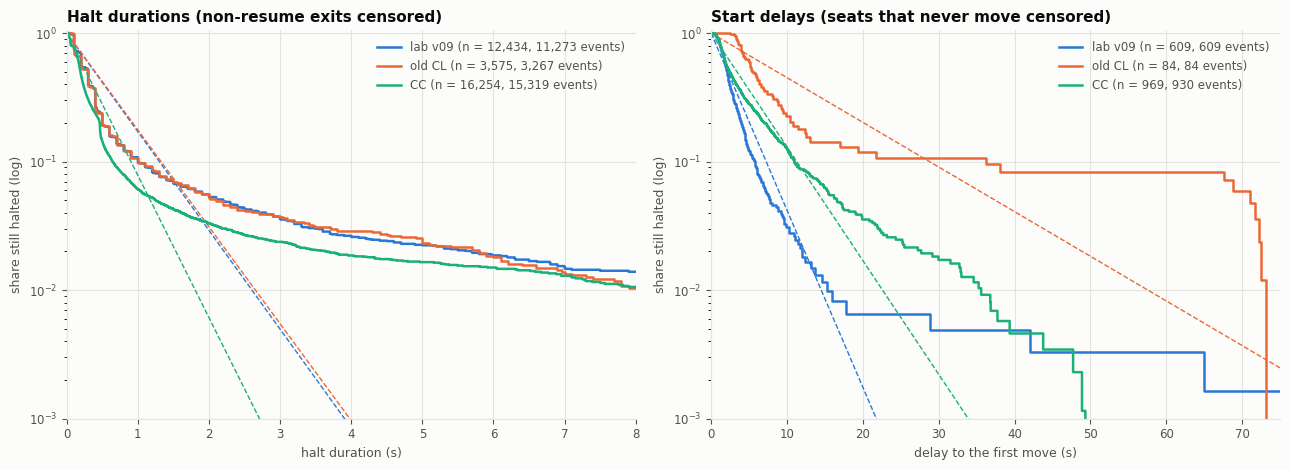

,spell,interface,n,events,mean_s,sd_s,km_median_s,one_over_lam_s
0,halt,lab_v09,12434,11273,0.416,1.009,0.300,0.566
1,halt,old_cl,3575,3267,0.529,1.588,0.300,0.576
2,halt,cc,16254,15319,0.317,0.933,0.192,0.392
3,start,lab_v09,609,609,3.153,5.596,2.060,3.153
4,start,old_cl,84,84,12.506,18.703,5.390,12.506
5,start,cc,969,930,4.869,6.383,2.437,4.908


In [4]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = {"lab_v09": "#2a78d6", "old_cl": "#eb6834", "cc": "#1baf7a"}
NAMES = {"lab_v09": "lab v09", "old_cl": "old CL", "cc": "CC"}
lam = rates.set_index(["interface", "rate"])["estimate"]

halt = pd.DataFrame({"interface": halts["interface"], "duration": halts["duration"],
                     "event": (halts["exit"] == "resume").astype(int)})
start = pd.DataFrame({"interface": seats["interface"], "duration": seats["start_delay"].fillna(seats["pre_s"]),
                      "event": seats["moved"]})
panels = [(halt, "lam_resume", "Halt durations (non-resume exits censored)", "halt duration (s)", 8),
          (start, "lam_start", "Start delays (seats that never move censored)", "delay to the first move (s)", 75)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), facecolor=SURFACE)
summary = []
for ax, (d, rate, title, xlabel, xmax) in zip(axes, panels):
    for name in motion.INTERFACES:
        x = d[d["interface"] == name]
        km, median = kaplan_meier(x["duration"], x["event"])
        ax.step(np.r_[0, km["time"]], np.r_[1, km["survival"]], where="post", color=COLORS[name], linewidth=1.8,
                label=f"{NAMES[name]} (n = {len(x):,}, {int(x['event'].sum()):,} events)")
        tt = np.linspace(0, xmax, 300)
        ax.plot(tt, np.exp(-lam[(name, rate)] * tt), color=COLORS[name], linewidth=1, linestyle="--")
        done = x.loc[x["event"] == 1, "duration"]
        summary.append({"spell": "halt" if rate == "lam_resume" else "start", "interface": name, "n": len(x),
                        "events": len(done), "mean_s": done.mean(), "sd_s": done.std(ddof=1),
                        "km_median_s": median, "one_over_lam_s": 1 / lam[(name, rate)]})
    ax.set_yscale("log")
    ax.set_xlim(0, xmax)
    ax.set_ylim(1e-3, 1.05)
    ax.set_title(title, loc="left", fontsize=11, color=INK, fontweight="bold")
    ax.set_xlabel(xlabel, color=INK_2, fontsize=9)
    ax.set_ylabel("share still halted (log)", color=INK_2, fontsize=9)
    ax.set_facecolor(SURFACE)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=8.5)
    ax.legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="upper right")
fig.tight_layout()
fig.savefig(config.P17_SURVIVAL, dpi=150, facecolor=SURFACE)
plt.show()
pd.DataFrame(summary).round(3)

## First move toward the neighbors' majority side

In [5]:
follow = motion.follow_table(seats)
moved = seats[seats["moved"] == 1]
print(len(moved), "first moves;", int(moved["nbr_side"].isna().sum()), "with no neighbor majority (none moved, or a tie)")
follow.round(4)

1623 first moves; 679 with no neighbor majority (none moved, or a tie)


,interface,first_moves,toward,share,ci_low,ci_high,groups
0,lab_v09,356,197,0.5534,0.5000,0.6067,20
1,old_cl,51,28,0.5490,0.4545,0.6207,2
2,cc,537,258,0.4804,0.4492,0.5117,17
3,shared,944,483,0.5117,0.4833,0.5405,39


## Verdicts of the two locked rules

In [6]:
ci = rates.set_index(["interface", "rate"])[["ci_low", "ci_high"]]
disjoint = {}
for name in motion.INTERFACES:
    s, r = ci.loc[(name, "lam_start")], ci.loc[(name, "lam_resume")]
    disjoint[name] = bool(s["ci_high"] < r["ci_low"] or r["ci_high"] < s["ci_low"])
    print(f"{name:8s} lam_start CI [{s['ci_low']:.3f}, {s['ci_high']:.3f}]  lam_resume CI [{r['ci_low']:.3f}, {r['ci_high']:.3f}]"
          f"  disjoint: {disjoint[name]}")
n = sum(disjoint.values())
print(f"(a) Start rule: disjoint in {n} of 3 ->", "separate lam_start" if n >= 2 else "start = first resume")

f = follow.set_index("interface").loc["shared"]
print(f"(b) Direction rule: share toward the majority {f['share']:.3f}, 95% CI [{f['ci_low']:.3f}, {f['ci_high']:.3f}]"
      " ->", "follow neighbors" if f["ci_low"] > 0.5 else "coin flip")

lab_v09  lam_start CI [0.268, 0.371]  lam_resume CI [1.477, 2.065]  disjoint: True
old_cl   lam_start CI [0.056, 0.138]  lam_resume CI [1.560, 2.166]  disjoint: True
cc       lam_start CI [0.183, 0.228]  lam_resume CI [2.183, 2.991]  disjoint: True
(a) Start rule: disjoint in 3 of 3 -> separate lam_start
(b) Direction rule: share toward the majority 0.512, 95% CI [0.483, 0.540] -> coin flip


## F1b: old -> new (p17_rates_v1.csv -> p17_rates.csv)

In [7]:
old = pd.read_csv(config.P17_RATES_V1).set_index(["interface", "rate"])
new = rates.set_index(["interface", "rate"])
cmp = pd.DataFrame({"old": old["estimate"], "new": new["estimate"], "old ci": old["ci_low"].round(3).astype(str) + " - " + old["ci_high"].round(3).astype(str),
                    "new ci": new["ci_low"].round(3).astype(str) + " - " + new["ci_high"].round(3).astype(str),
                    "old exposure_s": old["exposure_s"], "new exposure_s": new["exposure_s"]})
cmp["new / old"] = cmp["new"] / cmp["old"]
cmp.round(4)

old      new          old ci         new ci  old exposure_s  new exposure_s  new / old
interface rate                                                                                                  
lab_v09   lam_stop     3.0393   3.2590   2.485 - 3.533  2.681 - 3.777       3610.7000       3367.2500     1.0723
          lam_resume   1.7681   1.7681   1.477 - 2.065  1.477 - 2.065       6375.9000       6375.9000     1.0000
          lam_start    0.3171   0.3171   0.268 - 0.371  0.268 - 0.371       1920.4700       1920.4700     1.0000
old_cl    lam_stop     1.7603   1.8040   1.697 - 1.888  1.747 - 1.919       1944.6000       1897.5000     1.0248
          lam_resume   1.7356   1.7356    1.56 - 2.166   1.56 - 2.166       1882.3300       1882.3300     1.0000
          lam_start    0.0800   0.0800   0.056 - 0.138  0.056 - 0.138       1050.5400       1050.5400     1.0000
cc        lam_stop    10.3500  11.1014  8.799 - 12.057  9.42 - 12.931       1421.9294       1325.6862     1.0726
          lam_resume   2.5491   2.5491   2.183 - 2.991  2.183 - 2.991       6009.5436       6009.5436     1.0000
          lam_start    0.2037   0.2037   0.183 - 0.228  0.183 - 0.228       4564.6462       4564.6462     1.0000
shared    lam_stop     4.1727   4.4176   3.303 - 5.283   3.467 - 5.65       6977.2294       6590.4362     1.0587
          lam_resume   2.0928   2.0928   1.864 - 2.348  1.864 - 2.348      14267.7736      14267.7736     1.0000
          lam_start    0.2154   0.2154   0.179 - 0.251  0.179 - 0.251       7535.6562       7535.6562     1.0000